# Ecommerce Sales Analysis

## Objective

The objective of this project is to analyse e-commerce
transaction data to identify sales trends, top performing 
products, customer behaviour, and geographical patterns.

In [ ]:
%pip install pandas numpy matplotlib seaborn openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_excel("../data/online retail.xlsx/Online Retail.xlsx")

In [6]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
df.shape
# (rows,columns)

(541909, 8)

In [8]:
df.columns
# what columns are present in the dataset

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [9]:
df.info()
# what is the data type of each column

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [10]:
df.describe()
# what is the statistical summary of the dataset

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [11]:
df.isnull().sum()
# for the null values in the dataset, we can see that there are 135080 null values in the 'CustomerID' column and 1454 null values in the 'Description' column. We can drop these columns as they are not useful for our analysis.

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [12]:
df.duplicated().sum()
# duplicated rows in the dataset, we can see that there are 5268 duplicated rows in the dataset. We can drop these rows as they are not useful for our analysis.

np.int64(5268)

In [13]:
df_clean = df.copy()

In [14]:
df_clean.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [15]:
# in this the invoice numbers starting with 'C' are the cancelled orders. 
df_clean['InvoiceNo'].astype(str).str.startswith('C').sum()
# this will identify all the invoice no. starting with 'c' 

np.int64(9288)

In [16]:
# Negative quantities
(df_clean['Quantity'] <= 0).sum()

np.int64(10624)

In [17]:
# Check for negative/zero prices
(df_clean['UnitPrice'] <= 0).sum()

np.int64(2517)

In [18]:
df_clean.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [19]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [20]:
# for proper date time column
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

In [21]:
df_clean['InvoiceDate'].dtype

dtype('<M8[us]')

In [22]:
df_clean['Revenue']= df_clean['Quantity'] * df_clean['UnitPrice']

In [23]:
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [24]:
df_sales = df_clean[
    (~df_clean['InvoiceNo'].astype(str).str.startswith('C')) &
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
].copy()

In [25]:
df_sales.shape

(530104, 9)

In [26]:
df_sales['InvoiceNo'].astype(str).str.startswith('C').sum()

np.int64(0)

In [27]:
(df_sales['Quantity'] <= 0).sum()

np.int64(0)

In [28]:
(df_sales['UnitPrice'] <= 0).sum()

np.int64(0)

In [29]:
df_sales.duplicated().sum()

np.int64(5226)

In [30]:
df_sales[df_sales.duplicated()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,2.95


In [31]:
df_sales[df_sales.duplicated()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,2.95
587,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,2.95
589,536412,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-01 11:49:00,3.75,17920.0,United Kingdom,3.75
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom,2.10
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom,1.65
600,536412,22569,FELTCRAFT CUSHION BUTTERFLY,2,2010-12-01 11:49:00,3.75,17920.0,United Kingdom,7.50


In [32]:
df_sales_clean = df_sales.drop_duplicates().copy()

In [33]:
df_sales_clean.shape

(524878, 9)

In [34]:
df_sales_clean.duplicated().sum()

np.int64(0)

In [35]:
df_sales_clean['Year']= df_sales_clean['InvoiceDate'].dt.year

In [36]:
df_sales_clean['Month']= df_sales_clean['InvoiceDate'].dt.month

In [37]:
df_sales_clean['Month_name']= df_sales_clean['InvoiceDate'].dt.month_name()   

In [38]:
df_sales_clean['Day_name']= df_sales_clean['InvoiceDate'].dt.day_name()   

In [39]:
df_sales_clean['Hour']= df_sales_clean['InvoiceDate'].dt.hour

In [40]:
df_sales_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,Month_name,Day_name,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,December,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,December,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,Wednesday,8


In [41]:
df_sales_clean.shape

(524878, 14)

In [42]:
df_sales_clean.isnull().sum()
# here the null customer id are not removed because we can use the customeer id for product and sales analysis. So we will keep the null values in the customer id column.

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
Year                0
Month               0
Month_name          0
Day_name            0
Hour                0
dtype: int64

In [43]:
total_revenue = df_sales_clean['Revenue'].sum()
print('Total Revenue:', total_revenue)

Total Revenue: 10642110.804000001


In [44]:
total_quantities = df_sales_clean['Quantity'].sum()
print('Total Quantities Sold:', total_quantities)

Total Quantities Sold: 5572420


In [45]:
unique_orders = df_sales_clean['StockCode'].nunique()
print('Total Unique Products Sold:', unique_orders)

Total Unique Products Sold: 3922


In [46]:
unique_countries = df_sales_clean['Country'].nunique()
print('Total Unique Countries:', unique_countries)  

Total Unique Countries: 38


In [47]:
total_orders = df_sales_clean['InvoiceNo'].nunique()
print('Total Orders:', total_orders)

Total Orders: 19960


In [48]:
# top 10 products by revenue
top_products = (
    df_sales_clean.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending = False)
    .head(10)
)
top_products

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

In [49]:
# top 10 products by Quantity
top_products = (
    df_sales_clean.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending = False)
    .head(10)
)
top_products

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

In [52]:
# Rebuild monthly_sales from the cleaned sales data
monthly_sales = (
    df_sales_clean.groupby(['Year', 'Month'], as_index=False)['Revenue']
    .sum()
)

# Make sure Month is 2-digit for date creation
monthly_sales['Date'] = pd.to_datetime(
    monthly_sales['Year'].astype(str) + '-' +
    monthly_sales['Month'].astype(str).str.zfill(2) + '-01'
)

# Sort by date
monthly_sales = monthly_sales.sort_values('Date').reset_index(drop=True)
monthly_sales.head()

,Year,Month,Revenue,Date
0,2010,12,821452.730,2010-12-01
1,2011,1,689811.610,2011-01-01
2,2011,2,522545.560,2011-02-01
3,2011,3,716215.260,2011-03-01
4,2011,4,536968.491,2011-04-01


In [55]:
# which month had the highest revenue
monthly_sales.loc[
    monthly_sales['Revenue'].idxmax()
]

Year                      2011
Month                       11
Revenue             1503866.78
Date       2011-11-01 00:00:00
Name: 11, dtype: object

In [56]:
# which month had the lowest revenue
monthly_sales.loc[
    monthly_sales['Revenue'].idxmin()
]

Year                      2011
Month                        2
Revenue              522545.56
Date       2011-02-01 00:00:00
Name: 2, dtype: object

In [57]:
revenue_difference = monthly_sales['Revenue'].max() - monthly_sales['Revenue'].min()
print("Revenue Difference:", revenue_difference)

Revenue Difference: 981321.22


In [58]:
# Revenue each year

yearly_sales = df_sales_clean.groupby(['Year'], as_index=False)['Revenue'].sum()

print(yearly_sales)

   Year      Revenue
0  2010   821452.730
1  2011  9820658.074


In [59]:
# revenue of top 10 products
product_revenue = (
    df_sales_clean.groupby('Description', as_index=False)['Revenue']
    .sum()
    .sort_values('Revenue', ascending=False)
    .reset_index(drop=True)
)
print(product_revenue.head(10))

                          Description    Revenue
0                      DOTCOM POSTAGE  206248.77
1            REGENCY CAKESTAND 3 TIER  174156.54
2         PAPER CRAFT , LITTLE BIRDIE  168469.60
3  WHITE HANGING HEART T-LIGHT HOLDER  106236.72
4                       PARTY BUNTING   99445.23
5             JUMBO BAG RED RETROSPOT   94159.81
6      MEDIUM CERAMIC TOP STORAGE JAR   81700.92
7                             POSTAGE   78101.88
8                              Manual   77752.82
9                  RABBIT NIGHT LIGHT   66870.03


In [60]:
%matplotlib inline

In [65]:
print(product_revenue.head(10))

                          Description    Revenue
0                      DOTCOM POSTAGE  206248.77
1            REGENCY CAKESTAND 3 TIER  174156.54
2         PAPER CRAFT , LITTLE BIRDIE  168469.60
3  WHITE HANGING HEART T-LIGHT HOLDER  106236.72
4                       PARTY BUNTING   99445.23
5             JUMBO BAG RED RETROSPOT   94159.81
6      MEDIUM CERAMIC TOP STORAGE JAR   81700.92
7                             POSTAGE   78101.88
8                              Manual   77752.82
9                  RABBIT NIGHT LIGHT   66870.03


In [66]:
print(product_revenue.shape)

(4026, 2)


In [67]:
print(df_clean[['Description', 'Revenue']].head())

                           Description  Revenue
0   WHITE HANGING HEART T-LIGHT HOLDER    15.30
1                  WHITE METAL LANTERN    20.34
2       CREAM CUPID HEARTS COAT HANGER    22.00
3  KNITTED UNION FLAG HOT WATER BOTTLE    20.34
4       RED WOOLLY HOTTIE WHITE HEART.    20.34


In [69]:
df[df['Description'].str.contains(
    'POSTAGE|MANUAL',
    case=False,
    na= False
    ) 
]['Description'].value_counts()

Description
POSTAGE           1252
DOTCOM POSTAGE     709
Manual             572
Name: count, dtype: int64

In [70]:
product_df = df[
    ~df['Description'].isin([
        'POSTAGE'
        'DOTCOM POSTAGE',
        'Manual'
    ])
].copy()

In [71]:
product_revenue = (
    df_sales_clean[
        ~df_sales_clean['Description'].str.contains(
            'POSTAGE|MANUAL',
            case=False,
            na=False
        )
    ]
    .groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
)


In [72]:
top_10_products = product_revenue.head(10).reset_index()

top_10_products

,Description,Revenue
0,REGENCY CAKESTAND 3 TIER,174156.54
1,"PAPER CRAFT , LITTLE BIRDIE",168469.60
2,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
3,PARTY BUNTING,99445.23
4,JUMBO BAG RED RETROSPOT,94159.81
5,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
6,RABBIT NIGHT LIGHT,66870.03
7,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59
8,ASSORTED COLOUR BIRD ORNAMENT,58927.62
9,CHILLI LIGHTS,54096.36


In [73]:
product_quantity = (
    df_sales_clean[
        ~df_sales_clean['Description'].str.contains(
            'POSTAGE|MANUAL',
            case=False,
            na=False
        )
    ]
    .groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

In [74]:
top_10_products = product_quantity.head(10).reset_index()

top_10_products

,Description,Quantity
0,"PAPER CRAFT , LITTLE BIRDIE",80995
1,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,JUMBO BAG RED RETROSPOT,48371
4,WHITE HANGING HEART T-LIGHT HOLDER,37872
5,POPCORN HOLDER,36749
6,PACK OF 72 RETROSPOT CAKE CASES,36396
7,ASSORTED COLOUR BIRD ORNAMENT,36362
8,RABBIT NIGHT LIGHT,30739
9,MINI PAINT SET VINTAGE,26633


In [75]:
# Top customers by revenue
top_10_customers = (
    df_sales_clean
    .groupby('CustomerID', as_index=False)['Revenue']
    .sum()
    .sort_values('Revenue', ascending=False)
    .head(10)
    .reset_index(drop=True)
)
print(top_10_customers.head(10))

   CustomerID    Revenue
0     14646.0  280206.02
1     18102.0  259657.30
2     17450.0  194390.79
3     16446.0  168472.50
4     14911.0  143711.17
5     12415.0  124914.53
6     14156.0  117210.08
7     17511.0   91062.38
8     16029.0   80850.84
9     12346.0   77183.60


In [76]:
# top customers by number of orders
top_10_customers = (
    df_sales_clean
    .groupby('CustomerID', as_index=False)['InvoiceNo']
    .nunique()
    .sort_values('InvoiceNo', ascending=False)
    .head(10)
    .reset_index(drop=True)
)
print(top_10_customers.head(10))

   CustomerID  InvoiceNo
0     12748.0        209
1     14911.0        201
2     17841.0        124
3     13089.0         97
4     14606.0         93
5     15311.0         91
6     12971.0         86
7     14646.0         73
8     16029.0         63
9     13408.0         62


In [77]:
# country revenue
country_revenue = (
    df_sales_clean
    .groupby('Country', as_index=False)['Revenue']
    .sum()
    .sort_values('Revenue', ascending=False)
    .head(10)
    .reset_index(drop=True)
)
print(country_revenue.head(10))

          Country      Revenue
0  United Kingdom  9001744.094
1     Netherlands   285446.340
2            EIRE   283140.520
3         Germany   228678.400
4          France   209625.370
5       Australia   138453.810
6           Spain    61558.560
7     Switzerland    57067.600
8         Belgium    41196.340
9          Sweden    38367.830


In [78]:
# top countries by number of orders
top_10_country_orders = (
    df_sales_clean
    .groupby('Country', as_index=False)['InvoiceNo']
    .nunique()
    .sort_values('InvoiceNo', ascending=False)
    .head(10)
    .reset_index(drop=True)
)
print(top_10_country_orders.head(10))

          Country  InvoiceNo
0  United Kingdom      18019
1         Germany        457
2          France        392
3            EIRE        288
4         Belgium         98
5     Netherlands         94
6           Spain         90
7        Portugal         58
8       Australia         57
9     Switzerland         54


In [79]:
total_revenue = df_sales_clean['Revenue'].sum()
total_orders = df_sales_clean['InvoiceNo'].nunique()

average_order_value = total_revenue / total_orders

average_order_value

np.float64(533.171883967936)

In [80]:
# Average no. of items per order
items_per_order = (
    df_sales_clean
    .groupby('InvoiceNo')['Quantity']
    .sum()
)
average_items_per_order = items_per_order.mean()

average_items_per_order


np.float64(279.17935871743487)

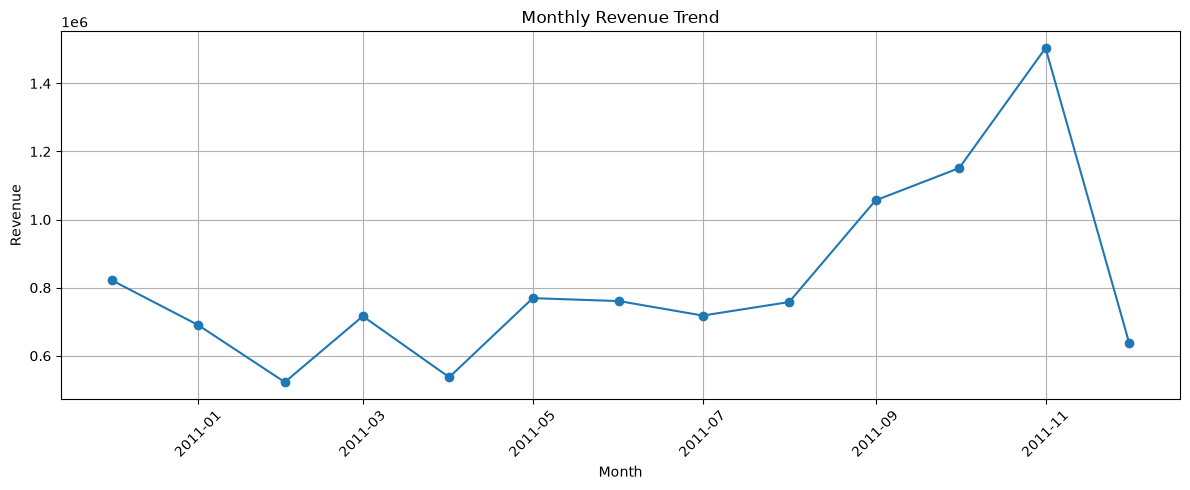

In [82]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_sales["Date"],
    monthly_sales["Revenue"],
    marker="o"
)

ax.set_title('Monthly Revenue Trend')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue')
ax.tick_params(axis='x', rotation=45)
ax.grid(True)

fig.tight_layout()
plt.savefig(
    '../images/monthly_revenue_trend.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

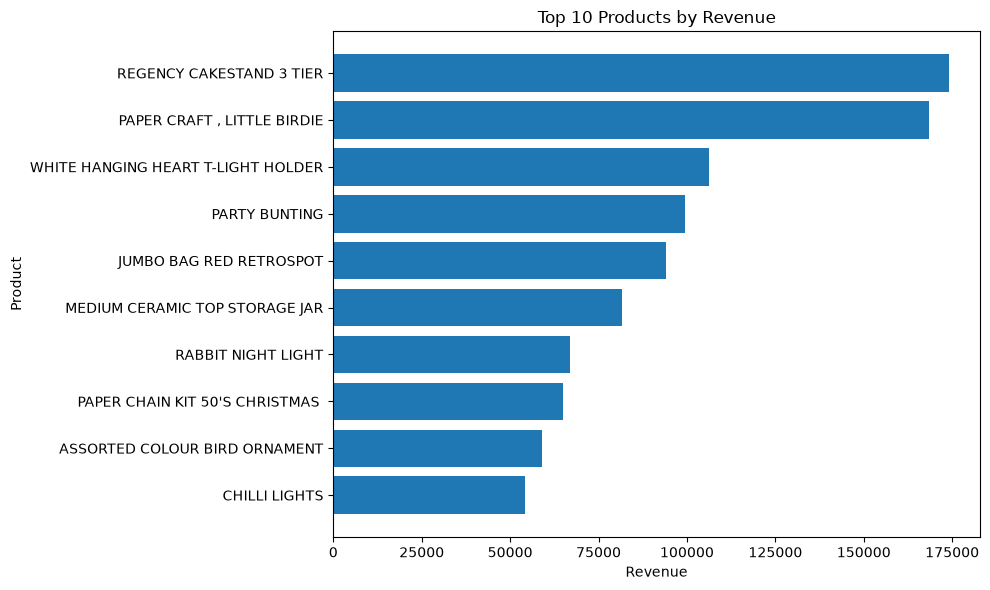

In [83]:
import matplotlib.pyplot as plt

top_10_products = product_revenue.head(10)

fig, ax = plt.subplots(figsize=(10, 6))

top_10_products = product_revenue.head(10).reset_index()
top_10_products.columns = ['Description', 'Revenue']

ax.barh(
    top_10_products['Description'].astype(str),
    top_10_products['Revenue']
)

ax.set_xlabel('Revenue')
ax.set_ylabel('Product')
ax.set_title('Top 10 Products by Revenue')
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(
    '../images/top_products_by_revenue.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.show()

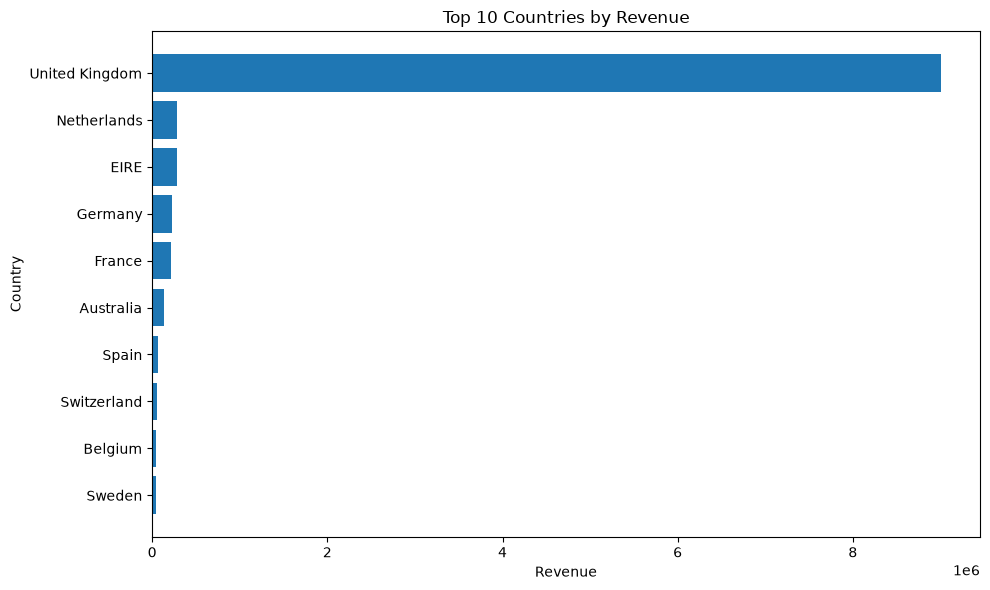

In [71]:
# country wise revenue chart
top_10_countries = country_revenue.head(10)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_10_countries['Country'].astype(str),
    top_10_countries['Revenue']
)

ax.set_xlabel('Revenue')
ax.set_ylabel('Country')
ax.set_title('Top 10 Countries by Revenue')

ax.invert_yaxis()
plt.tight_layout()
plt.show()

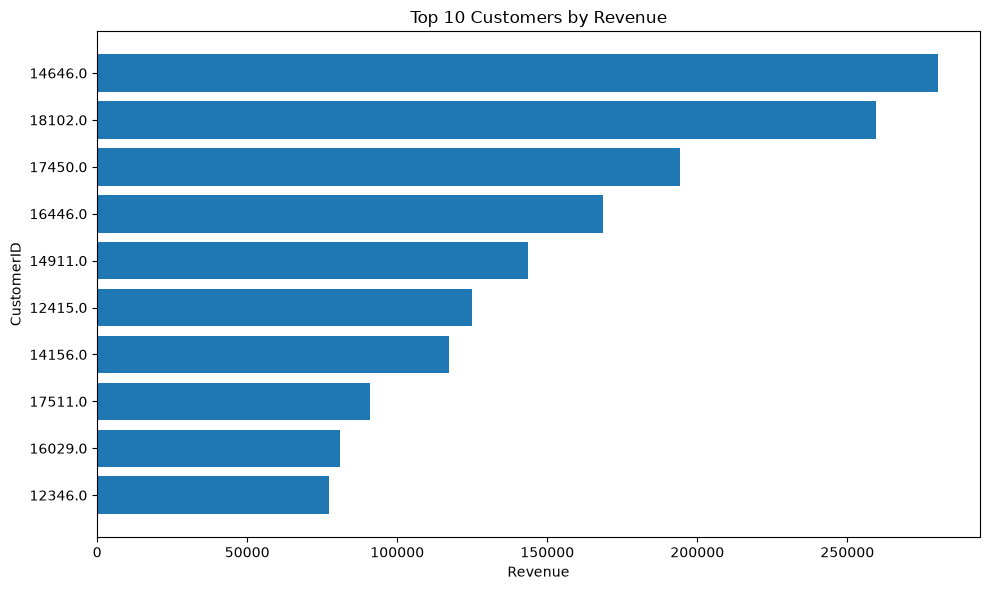

In [84]:
top_10_customers_revenue = top_10_customers.head(10)

fig, ax = plt.subplots(figsize=(10, 6))

top_10_customers_revenue = (
    df_sales_clean
    .groupby('CustomerID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

ax.barh(
    top_10_customers_revenue['CustomerID'].astype(str),
    top_10_customers_revenue['Revenue']
)

ax.set_xlabel('Revenue')
ax.set_ylabel('CustomerID')
ax.set_title('Top 10 Customers by Revenue')

ax.invert_yaxis()
plt.tight_layout()
plt.savefig(
    '../images/top_customers_by_revenue.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.show()

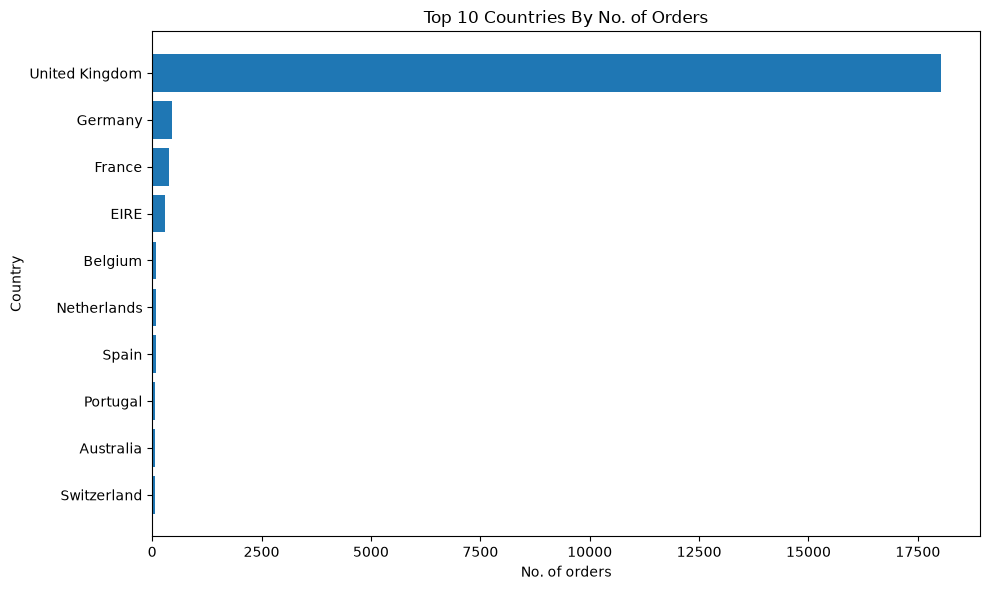

In [85]:
top_10_country_orders= top_10_country_orders.head(10)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

top_10_country_orders = (
    df_sales_clean
    .groupby('Country', as_index=False)['InvoiceNo']
    .nunique()
    .sort_values('InvoiceNo', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

ax.barh(
    top_10_country_orders['Country'].astype(str),
    top_10_country_orders['InvoiceNo']
)

ax.set_xlabel('No. of orders')
ax.set_ylabel('Country')
ax.set_title('Top 10 Countries By No. of Orders')

ax.invert_yaxis()
plt.tight_layout()
plt.savefig(
    '../images/top_country_by_orders.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.show()

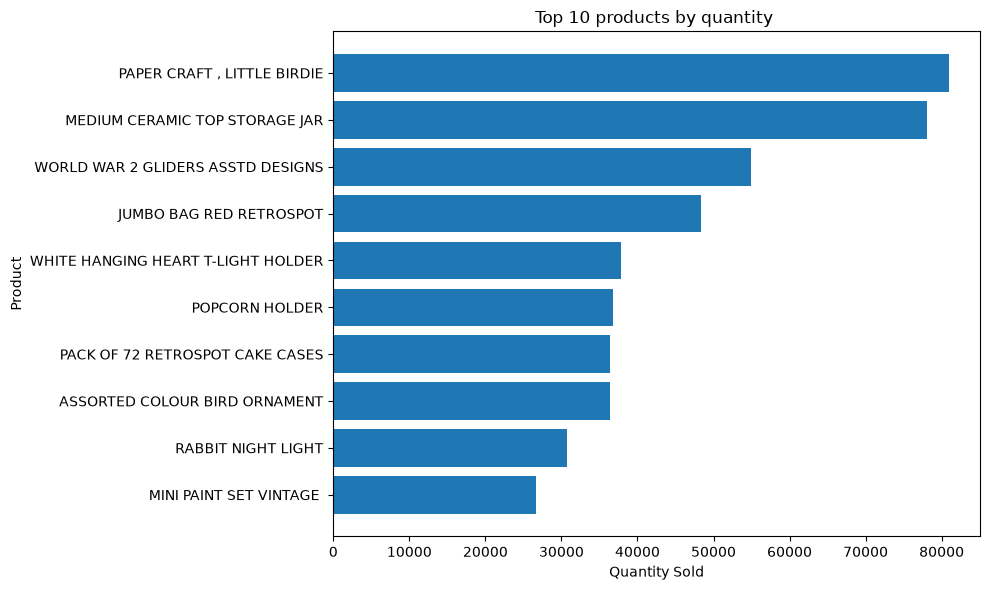

In [86]:
import matplotlib.pyplot as plt

product_quantity = (
    df_sales_clean[
        ~df_sales_clean['Description'].str.contains(
            'POSTAGE|MANUAL',
            case=False,
            na=False
        )
    ]
    .groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

top_10_products_quantity = product_quantity.head(10)

fig, ax = plt.subplots(figsize=(10,6))

ax.barh(
    top_10_products_quantity['Description'],
    top_10_products_quantity['Quantity']
)

ax.set_xlabel('Quantity Sold')
ax.set_ylabel('Product')
ax.set_title('Top 10 products by quantity ')

ax.invert_yaxis()
plt.tight_layout()
plt.savefig(
    '../images/top_product_by_quantity.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [87]:
print("Highest Revenue Month:")
print(monthly_sales.loc[monthly_sales['Revenue'].idxmax()])

print("\nLowest Revenue Month:")
print(monthly_sales.loc[monthly_sales['Revenue'].idxmin()])

print("\nTop 5 Products by Revenue:")
print(product_revenue.head(5))

print("\nTop 5 Countries by Revenue:")
print(country_revenue.head(5))

print("\nTop 5 Customers by Orders:")
print(top_10_customers.head(5))

Highest Revenue Month:
Year                      2011
Month                       11
Revenue             1503866.78
Date       2011-11-01 00:00:00
Name: 11, dtype: object

Lowest Revenue Month:
Year                      2011
Month                        2
Revenue              522545.56
Date       2011-02-01 00:00:00
Name: 2, dtype: object

Top 5 Products by Revenue:
Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
Name: Revenue, dtype: float64

Top 5 Countries by Revenue:
          Country      Revenue
0  United Kingdom  9001744.094
1     Netherlands   285446.340
2            EIRE   283140.520
3         Germany   228678.400
4          France   209625.370

Top 5 Customers by Orders:
   CustomerID  InvoiceNo
0     12748.0        209
1     14911.0        201
2     17841.0        124
3     

## Business Insights

### 1. Monthly Revenue Trend

November 2011 recorded the highest monthly revenue of approximately 1,503,867, while February 2011 recorded the lowest revenue of approximately 522,546. This indicates considerable variation in monthly sales during the analyzed period.

### 2. Top-Performing Products

Regency Cakestand 3 Tier generated the highest revenue among the listed products, approximately 174,156.54. Paper Craft, Little Birdie followed with approximately 168,469.60. These products were important revenue contributors.

### 3. Country-wise Revenue

The United Kingdom generated approximately 9,001,744.09 in revenue, substantially more than any other country in the dataset. The Netherlands, EIRE, Germany, and France were the next four countries among the top five.

### 4. Frequent Customers

Customer 12748 placed 209 unique orders, followed by Customer 14911 with 201 orders. These customers were the most frequent purchasers among those listed in the customer order analysis.

### 5. Business Opportunity

The business could investigate why revenue varies across months and explore opportunities to increase sales in markets outside the United Kingdom. Further analysis would be needed before recommending specific actions.




## Conclusion

This project analyzed the Online Retail dataset to understand sales performance, product revenue, customer purchasing behaviour, and country-wise sales. Data cleaning and exploratory data analysis helped identify monthly revenue trends, top-performing products, leading markets, and frequent customers.

November 2011 recorded the highest monthly revenue, while February 2011 recorded the lowest. The United Kingdom was the leading market by revenue, and Regency Cakestand 3 Tier was the highest-revenue product among the filtered products.

Overall, this project demonstrates how Python libraries such as Pandas, Matplotlib, and Seaborn can be used to clean data, explore patterns, create visualizations, and derive useful business insights.



In [88]:
import sqlite3
import pandas as pd

print("SQLite and Pandas are ready!")

SQLite and Pandas are ready!


In [89]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [90]:
import pandas as pd

file_path = "../data/online retail.xlsx/Online Retail.xlsx"

df_sql = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df_sql.shape)
print(df_sql.head())
print(df_sql.columns.tolist())

Dataset loaded successfully!
Shape: (541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [91]:
import sqlite3

conn = sqlite3.connect("../online_retail.db")

print("Database connection successful!")

Database connection successful!


In [92]:
df_sql.to_sql(
    "online_retail",
    conn,
    if_exists="replace",
    index=False
)

print("Data successfully loaded into SQLite!")

Data successfully loaded into SQLite!


In [93]:
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM online_retail")

print("Rows in SQLite:", cursor.fetchone()[0])

Rows in SQLite: 541909


In [94]:
cursor.execute("PRAGMA table_info(online_retail)")

for column in cursor.fetchall():
    print(column[1])

InvoiceNo
StockCode
Description
Quantity
InvoiceDate
UnitPrice
CustomerID
Country


In [95]:
import sqlite3

conn = sqlite3.connect("../online_retail.db")

print("Connected to SQLite!")

Connected to SQLite!


In [106]:
from pathlib import Path

sql_path = Path("../sql/sales_analysis.sql")

sql_text = sql_path.read_text(encoding="utf-8")

print(sql_text)


-- E-commerce Sales Analysis
-- Dataset: UCI Online Retail
-- Cleaned table: online_retail_clean

-- Query 1: Count cleaned records
SELECT COUNT(*) AS total_records
FROM online_retail_clean;

-- Query 2: Calculate total revenue
SELECT ROUND(SUM(Revenue), 2) AS total_revenue
FROM online_retail_clean;

-- Query 3: Top 10 products by revenue
-- Exclude postage and manual entries from product rankings
SELECT
    Description,
    ROUND(SUM(Revenue), 2) AS revenue
FROM online_retail_clean
WHERE Description IS NOT NULL
  AND UPPER(Description) NOT LIKE '%POSTAGE%'
  AND UPPER(Description) NOT LIKE '%MANUAL%'
GROUP BY Description
ORDER BY revenue DESC
LIMIT 10;

-- Query 4: Top 10 countries by revenue
SELECT
    Country,
    ROUND(SUM(Revenue), 2) AS revenue
FROM online_retail_clean
GROUP BY Country
ORDER BY revenue DESC
LIMIT 10;

-- Query 5: Monthly revenue
SELECT
    strftime('%Y-%m', InvoiceDate) AS month,
    ROUND(SUM(Revenue), 2) AS revenue
FROM online_retail_clean
GROUP BY strftime('%

In [107]:
import pandas as pd

queries = [
    query.strip()
    for query in sql_text.split(";")
    if query.strip() and "SELECT" in query.upper()
]

for i, query in enumerate(queries, start=1):
    print(f"\n{'=' * 50}")
    print(f"QUERY {i}")
    print("=" * 50)

    result = pd.read_sql_query(query, conn)
    display(result)


QUERY 1


,total_records
0,524878



QUERY 2


,total_revenue
0,10642110.8



QUERY 3


,Description,revenue
0,REGENCY CAKESTAND 3 TIER,174156.54
1,"PAPER CRAFT , LITTLE BIRDIE",168469.60
2,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
3,PARTY BUNTING,99445.23
4,JUMBO BAG RED RETROSPOT,94159.81
5,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
6,RABBIT NIGHT LIGHT,66870.03
7,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59
8,ASSORTED COLOUR BIRD ORNAMENT,58927.62
9,CHILLI LIGHTS,54096.36



QUERY 4


,Country,revenue
0,United Kingdom,9001744.09
1,Netherlands,285446.34
2,EIRE,283140.52
3,Germany,228678.40
4,France,209625.37
5,Australia,138453.81
6,Spain,61558.56
7,Switzerland,57067.60
8,Belgium,41196.34
9,Sweden,38367.83



QUERY 5


,month,revenue
0,2010-12,821452.73
1,2011-01,689811.61
2,2011-02,522545.56
3,2011-03,716215.26
4,2011-04,536968.49
5,2011-05,769296.61
6,2011-06,760547.01
7,2011-07,718076.12
8,2011-08,757841.38
9,2011-09,1056435.19


In [98]:
print("Cleaned data shape:", df_sales_clean.shape)
print("Total revenue:", df_sales_clean["Revenue"].sum())

Cleaned data shape: (524878, 14)
Total revenue: 10642110.804000001


In [99]:
df_sales_clean.to_sql(
    "online_retail_clean",
    conn,
    if_exists="replace",
    index=False
)

print("Cleaned data loaded into SQLite!")

Cleaned data loaded into SQLite!


In [100]:
sql_check = pd.read_sql_query("""
    SELECT
        COUNT(*) AS total_rows,
        ROUND(SUM(Quantity * UnitPrice), 3) AS total_revenue
    FROM online_retail_clean
""", conn)

display(sql_check)

,total_rows,total_revenue
0,524878,1.064211e+07


In [101]:
sql_monthly = pd.read_sql_query("""
    SELECT
        substr(InvoiceDate, 1, 7) AS month,
        ROUND(SUM(Quantity * UnitPrice), 2) AS revenue
    FROM online_retail_clean
    GROUP BY substr(InvoiceDate, 1, 7)
    ORDER BY month
""", conn)

display(sql_monthly)

,month,revenue
0,2010-12,821452.73
1,2011-01,689811.61
2,2011-02,522545.56
3,2011-03,716215.26
4,2011-04,536968.49
5,2011-05,769296.61
6,2011-06,760547.01
7,2011-07,718076.12
8,2011-08,757841.38
9,2011-09,1056435.19


In [102]:
print("Columns:", df_sales_clean.columns.tolist())
print("Rows:", len(df_sales_clean))
print(df_sales_clean.head())

Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'Year', 'Month', 'Month_name', 'Day_name', 'Hour']
Rows: 524878
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Revenue  Year  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  2010   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  2010   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  2010   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom

In [103]:
conn.execute("DROP TABLE IF EXISTS online_retail_clean")

conn.execute("""
    CREATE TABLE online_retail_clean AS
    SELECT DISTINCT
        *,
        Quantity * UnitPrice AS Revenue
    FROM online_retail
    WHERE
        UPPER(TRIM(CAST(InvoiceNo AS TEXT))) NOT LIKE 'C%'
        AND Quantity > 0
        AND UnitPrice > 0
""")

print("Cleaned SQL table created successfully!")

Cleaned SQL table created successfully!


In [104]:
sql_summary = pd.read_sql_query("""
    SELECT
        COUNT(*) AS total_rows,
        ROUND(SUM(Revenue), 3) AS total_revenue
    FROM online_retail_clean
""", conn)

display(sql_summary)

print("Python rows:", len(df_sales_clean))
print("Python revenue:", round(df_sales_clean['Revenue'].sum(), 3))

,total_rows,total_revenue
0,524878,1.064211e+07


Python rows: 524878
Python revenue: 10642110.804
